The LHO wavefunction is given as:
$$
\psi_{n}(x) = \frac{1}{\sqrt{2^{n}n!}}\left(\frac{m\omega}{\hbar}\right)^{1/4}e^{\frac{-m\omega x^{2}}{2\hbar}}H_{n}\left(\sqrt{\frac{m\omega}{\hbar}}x\right)
$$
where, $H_{n}(x) = (-1)^{n}e^{x^{2}}\frac{d^{n}}{dz^{n}}\left(e^{-x^{2}}\right)$ are the Hermite Polynomials. <br> <br>
The energy eigenstates are given as:
$$
E_{n} = \left(n+\frac{1}{2}\right)\hbar\omega
$$

#### 1. IMPORTING NECESSARY PACKAGES

In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import numpy.polynomial.hermite as Herm
import math

#### 2. PLOTTING HERMITE POLYNOMIALS
In LHO, the hermite polynomials are given by $H_{\text{n}}(\xi)$, where, $\xi = \sqrt{\frac{m\omega}{\hbar}}x$

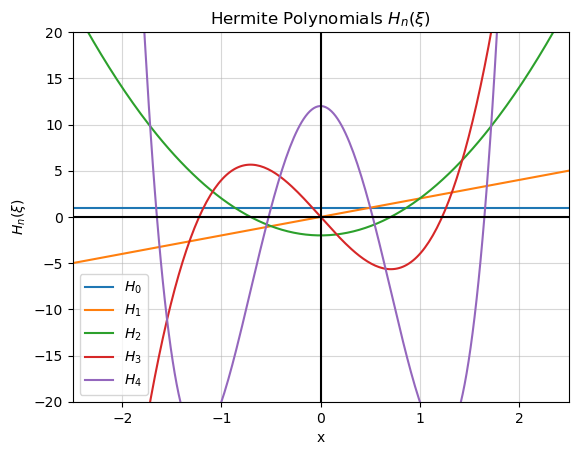

In [2]:
# Units scaled to 1
m = 1.
w = 1.
hbar = 1.

x = np.linspace(-10,10,1000)

def hermite(x,n): # Making the function that plots the hermite polynomials as per the LHO wavefunction
    xi = np.sqrt(m*w/hbar)*x
    herm_coeffs = np.zeros(n+1)
    herm_coeffs[n] = 1
    return (Herm.hermval(xi,herm_coeffs))

# Plotting the hermite polynomials
plt.plot(x,hermite(x,0),label=r"$H_0$")
plt.plot(x,hermite(x,1),label=r"$H_1$")
plt.plot(x,hermite(x,2),label=r"$H_2$")
plt.plot(x,hermite(x,3),label=r"$H_3$")
plt.plot(x,hermite(x,4),label=r"$H_4$")

plt.axhline(color='black')
plt.axvline(color='black')
plt.xlim(-2.5,2.5)
plt.ylim(-20,20)
plt.xlabel("x")
plt.ylabel(r"$H_n(\xi)$")
plt.title(r"Hermite Polynomials $H_n(\xi)$")
plt.grid(alpha=0.5)
plt.legend()

plt.show()

#### 3. TO PLOT THE STATIONARY STATES OF THE LHO

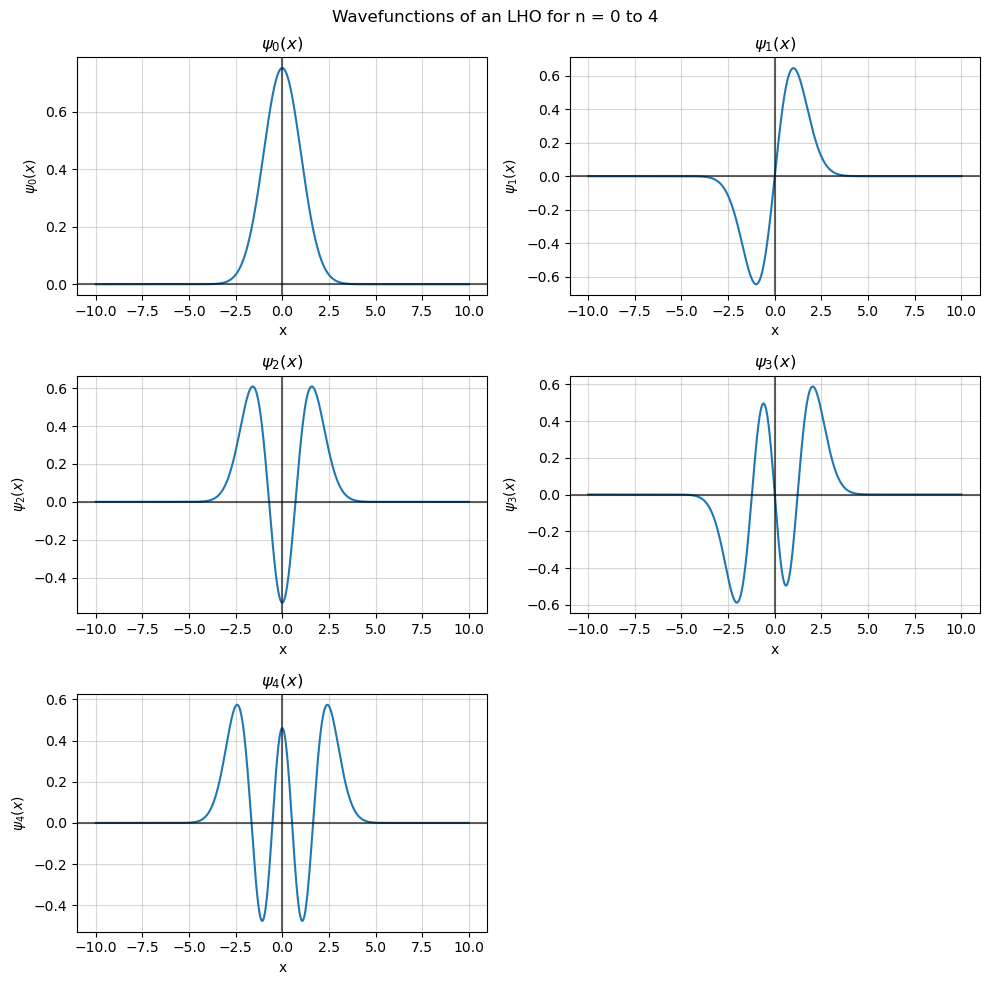

In [3]:
def state(x,n): # Function to generate stationary state values of the LHO
    xi = np.sqrt(m*w/hbar)*x
    psi = ((1/math.sqrt((2**n)*math.factorial(n)))*((m*w/(np.pi*hbar))**(1/4)))*(np.exp(-(xi**2)/2)*hermite(x,n))
    return (psi)

x = np.linspace(-10,10,1000)

fig,ax = plt.subplots(3,2,figsize=(10,10))  
ax = ax.flatten()

# Plotting the stationary states
for n in range(4):
    ax[n].plot(x,state(x,n))
    ax[n].set_title(fr"$\psi_{n}(x)$")
    ax[n].set_xlabel("x")
    ax[n].set_ylabel(fr"$\psi_{n}(x)$")
    ax[n].grid(alpha=0.5)
    ax[n].axhline(color='black',alpha=0.6)
    ax[n].axvline(color='black',alpha=0.6)
ax[4].plot(x,state(x,4))
ax[4].set_title(r"$\psi_{4}(x)$")
ax[4].set_xlabel("x")
ax[4].set_ylabel(r"$\psi_{4}(x)$")
ax[4].grid(alpha=0.5)
ax[4].axhline(color='black',alpha=0.6)
ax[4].axvline(color='black',alpha=0.6)
ax[5].axis("off")
plt.suptitle("Wavefunctions of an LHO for n = 0 to 4")

plt.tight_layout()

plt.show()

#### 4. TO PLOT THE PROBABILITY DENSITIES OF LHO

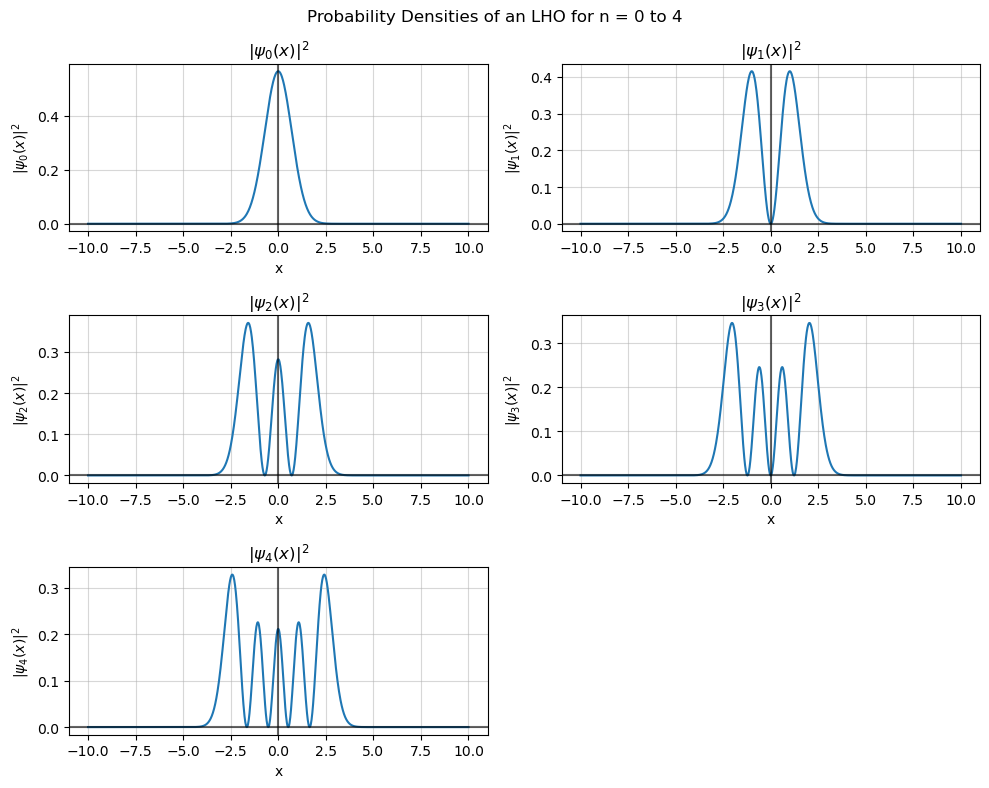

In [4]:
def pd(x,n): # Function to generate probability density values of the LHO
    xi = np.sqrt(m*w/hbar)*x
    psi = ((1/math.sqrt((2**n)*math.factorial(n)))*((m*w/(np.pi*hbar))**(1/4)))*(np.exp(-(xi**2)/2)*hermite(x,n))
    return (np.abs(psi)**2)

x = np.linspace(-10,10,1000)

fig,ax = plt.subplots(3,2,figsize=(10,8))  
ax = ax.flatten()

# Plotting the probability densities
for n in range(4):
    ax[n].plot(x,pd(x,n))
    ax[n].set_title(fr"$|\psi_{n}(x)|^{2}$")
    ax[n].set_xlabel("x")
    ax[n].set_ylabel(fr"$|\psi_{n}(x)|^{2}$")
    ax[n].grid(alpha=0.5)
    ax[n].axhline(color='black',alpha=0.6)
    ax[n].axvline(color='black',alpha=0.6)
plt.suptitle("Probability Densities of an LHO for n = 0 to 4")
ax[4].plot(x,pd(x,4))
ax[4].set_title(r"$|\psi_{4}(x)|^{2}$")
ax[4].set_xlabel("x")
ax[4].set_ylabel(r"$|\psi_{4}(x)|^{2}$")
ax[4].grid(alpha=0.5)
ax[4].axhline(color='black',alpha=0.6)
ax[4].axvline(color='black',alpha=0.6)
ax[5].axis("off")

plt.tight_layout()

plt.show()

#### 5. ENERGY EIGENSTATES OF AN LHO

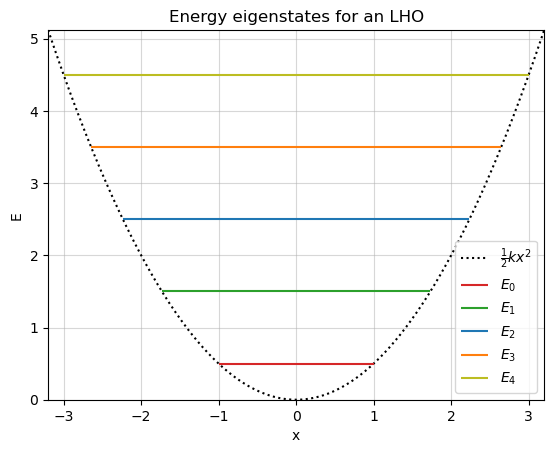

In [5]:
x = np.linspace(-3.2,3.2,1000)

def E(n): # Function to return LHO energy eigenstates
    return (n+0.5)

plt.plot(x,0.5*(x**2),color='black',linestyle='dotted',label=r"$\frac{1}{2}kx^{2}$") # Classical oscillator energy plot

# Oscillator energy plots for n = 0 to 4
plt.hlines(E(0),-np.sqrt(2*E(0)),np.sqrt(2*E(0)),color='tab:red',label=r"$E_{0}$")
plt.hlines(E(1),-np.sqrt(2*E(1)),np.sqrt(2*E(1)),color='tab:green',label=r"$E_{1}$")
plt.hlines(E(2),-np.sqrt(2*E(2)),np.sqrt(2*E(2)),color='tab:blue',label=r"$E_{2}$")
plt.hlines(E(3),-np.sqrt(2*E(3)),np.sqrt(2*E(3)),color='tab:orange',label=r"$E_{3}$")
plt.hlines(E(4),-np.sqrt(2*E(4)),np.sqrt(2*E(4)),color='tab:olive',label=r"$E_{4}$")

plt.xlim(-3.2,3.2)
plt.ylim(0,max(0.5*(x**2)))
plt.grid(alpha=0.5)
plt.legend(loc=4)
plt.xlabel("x")
plt.ylabel("E")
plt.title("Energy eigenstates for an LHO")

plt.show()

#### 6. COMPARISON BETWEEN CLASSICAL AND QUANTUM MECHANICAL EIGENSTATES
The classical probability is given as:
$$
P(x) = \frac{1}{\pi\sqrt{x_{\text{max}}^{2}-x^{2}}}
$$ where $|x| < x_{\text{max}}$ and $P(x)$ = 0 outside turning points. $x_{\text{max}}$ is given by: $x_{\text{max}} = \sqrt{\frac{2E}{m\omega^{2}}}$

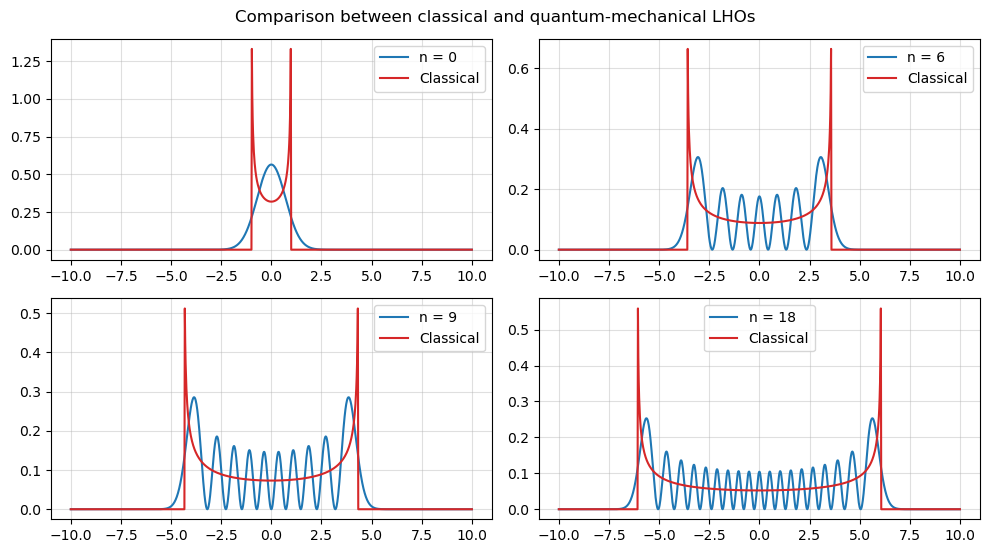

In [6]:
def classical_P(x,n):
    E = hbar*w*(n+0.5)
    x_max = np.sqrt(2*E/(m*(w**2)))
    classical_prob = np.zeros(x.shape[0])
    x_inside = abs(x)<(x_max-0.025)
    classical_prob[x_inside] = (1/np.pi)*1/(np.sqrt((x_max)**2-(x[x_inside]**2)))
    return (classical_prob)

x = np.linspace(-10,10,1000)

plt.figure(figsize=(10,8))
plt.subplot(3,2,1)
plt.plot(x,np.conjugate(pd(x,0)),label="n = 0")
plt.plot(x,classical_P(x,0),color='tab:red',label="Classical")
plt.grid(alpha=0.4)
plt.legend()
plt.subplot(3,2,2)
plt.plot(x,np.conjugate(pd(x,6)),label="n = 6")
plt.plot(x,classical_P(x,6),color='tab:red',label="Classical")
plt.grid(alpha=0.4)
plt.legend()
plt.subplot(3,2,3)
plt.plot(x,np.conjugate(pd(x,9)),label="n = 9")
plt.plot(x,classical_P(x,9),color='tab:red',label="Classical")
plt.grid(alpha=0.4)
plt.legend()
plt.subplot(3,2,4)
plt.plot(x,np.conjugate(pd(x,18)),label="n = 18")
plt.plot(x,classical_P(x,18),color='tab:red',label="Classical")
plt.grid(alpha=0.4)
plt.suptitle("Comparison between classical and quantum-mechanical LHOs")
plt.legend()

plt.tight_layout()

plt.show()